In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os

base = "/content/drive/MyDrive"

for root, dirs, files in os.walk(base):
    for file in files:
        if file in ["Dyt-desktop.csv", "Dyt-tablet.csv"]:
            print(os.path.join(root, file))

/content/drive/MyDrive/Dyslexia_Research_Model/Dytective  Rello et al. Online Gamified Dyslexia Test Dataset/Dyt-tablet.csv
/content/drive/MyDrive/Dyslexia_Research_Model/Dytective  Rello et al. Online Gamified Dyslexia Test Dataset/Dyt-desktop.csv


In [4]:
import os
import pandas as pd

desktop_path = None
tablet_path = None

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file == "Dyt-desktop.csv":
            desktop_path = os.path.join(root, file)
        elif file == "Dyt-tablet.csv":
            tablet_path = os.path.join(root, file)

print("Desktop:", desktop_path)
print("Tablet :", tablet_path)

desktop = pd.read_csv(desktop_path)
tablet = pd.read_csv(tablet_path)

print("\n========== DESKTOP ==========")
print("Shape:", desktop.shape)
print("Columns:")
print(desktop.columns.tolist())

print("\n========== TABLET ==========")
print("Shape:", tablet.shape)
print("Columns:")
print(tablet.columns.tolist())

Desktop: /content/drive/MyDrive/Dyslexia_Research_Model/Dytective  Rello et al. Online Gamified Dyslexia Test Dataset/Dyt-desktop.csv
Tablet : /content/drive/MyDrive/Dyslexia_Research_Model/Dytective  Rello et al. Online Gamified Dyslexia Test Dataset/Dyt-tablet.csv

========== DESKTOP ==========
Shape: (3644, 1)
Columns:
['Gender;Nativelang;Otherlang;Age;Clicks1;Hits1;Misses1;Score1;Accuracy1;Missrate1;Clicks2;Hits2;Misses2;Score2;Accuracy2;Missrate2;Clicks3;Hits3;Misses3;Score3;Accuracy3;Missrate3;Clicks4;Hits4;Misses4;Score4;Accuracy4;Missrate4;Clicks5;Hits5;Misses5;Score5;Accuracy5;Missrate5;Clicks6;Hits6;Misses6;Score6;Accuracy6;Missrate6;Clicks7;Hits7;Misses7;Score7;Accuracy7;Missrate7;Clicks8;Hits8;Misses8;Score8;Accuracy8;Missrate8;Clicks9;Hits9;Misses9;Score9;Accuracy9;Missrate9;Clicks10;Hits10;Misses10;Score10;Accuracy10;Missrate10;Clicks11;Hits11;Misses11;Score11;Accuracy11;Missrate11;Clicks12;Hits12;Misses12;Score12;Accuracy12;Missrate12;Clicks13;Hits13;Misses13;Score13;Acc

In [5]:
import pandas as pd

desktop = pd.read_csv(desktop_path, sep=";")
tablet = pd.read_csv(tablet_path, sep=";")

print("========== DESKTOP ==========")
print("Shape:", desktop.shape)
print("First 10 columns:", desktop.columns[:10].tolist())
print("Last 5 columns:", desktop.columns[-5:].tolist())

print("\nDyslexia counts:")
print(desktop["Dyslexia"].value_counts(dropna=False))

print("\n========== TABLET ==========")
print("Shape:", tablet.shape)
print("First 10 columns:", tablet.columns[:10].tolist())
print("Last 5 columns:", tablet.columns[-5:].tolist())

print("\nDyslexia counts:")
print(tablet["Dyslexia"].value_counts(dropna=False))

========== DESKTOP ==========
Shape: (3644, 197)
First 10 columns: ['Gender', 'Nativelang', 'Otherlang', 'Age', 'Clicks1', 'Hits1', 'Misses1', 'Score1', 'Accuracy1', 'Missrate1']
Last 5 columns: ['Misses32', 'Score32', 'Accuracy32', 'Missrate32', 'Dyslexia']

Dyslexia counts:
Dyslexia
No     3252
Yes     392
Name: count, dtype: int64

========== TABLET ==========
Shape: (1395, 197)
First 10 columns: ['Gender', 'Nativelang', 'Otherlang', 'Age', 'Clicks1', 'Hits1', 'Misses1', 'Score1', 'Accuracy1', 'Missrate1']
Last 5 columns: ['Misses32', 'Score32', 'Accuracy32', 'Missrate32', 'Dyslexia']

Dyslexia counts:
Dyslexia
No     1247
Yes     148
Name: count, dtype: int64


In [6]:
print("========== DATA TYPES ==========")
print(desktop.dtypes.value_counts())

print("\n========== MISSING VALUES ==========")
print("Desktop missing values:", desktop.isna().sum().sum())
print("Tablet missing values :", tablet.isna().sum().sum())

print("\n========== SAMPLE ==========")
display(desktop.head(3))

print("\n========== INTERACTION FEATURE SUMMARY ==========")

interaction_cols = [
    c for c in desktop.columns
    if c.startswith(("Clicks", "Hits", "Misses", "Score", "Accuracy", "Missrate"))
]

print("Number of interaction columns:", len(interaction_cols))
print("Expected:", 32 * 6)

print("\nFirst 12:")
print(interaction_cols[:12])

print("\nLast 12:")
print(interaction_cols[-12:])

print("\n========== VALUE RANGES ==========")
display(desktop[interaction_cols].describe().T.head(12))

========== DATA TYPES ==========
int64      129
float64     64
object       4
Name: count, dtype: int64

========== MISSING VALUES ==========
Desktop missing values: 0
Tablet missing values : 45650

========== SAMPLE ==========


,Gender,Nativelang,Otherlang,Age,Clicks1,Hits1,Misses1,Score1,Accuracy1,Missrate1,...,Score31,Accuracy31,Missrate31,Clicks32,Hits32,Misses32,Score32,Accuracy32,Missrate32,Dyslexia
0,Male,No,Yes,7,10,10,0,10,1.0,0.0,...,0,0.000000,0.0,17,2,0,2,0.117647,0.000000,No
1,Female,Yes,Yes,13,12,12,0,12,1.0,0.0,...,4,0.114286,0.0,26,2,2,2,0.076923,0.076923,Yes
2,Female,No,Yes,7,6,6,0,6,1.0,0.0,...,4,0.114286,0.0,26,1,3,1,0.038462,0.115385,No



========== INTERACTION FEATURE SUMMARY ==========
Number of interaction columns: 192
Expected: 192

First 12:
['Clicks1', 'Hits1', 'Misses1', 'Score1', 'Accuracy1', 'Missrate1', 'Clicks2', 'Hits2', 'Misses2', 'Score2', 'Accuracy2', 'Missrate2']

Last 12:
['Clicks31', 'Hits31', 'Misses31', 'Score31', 'Accuracy31', 'Missrate31', 'Clicks32', 'Hits32', 'Misses32', 'Score32', 'Accuracy32', 'Missrate32']

========== VALUE RANGES ==========


,count,mean,std,min,25%,50%,75%,max
Clicks1,3644.0,6.104281,4.473068,0.0,3.0,5.0,8.000000,84.0
Hits1,3644.0,3.683315,4.194311,0.0,0.0,1.0,7.000000,19.0
Misses1,3644.0,0.794731,1.191338,0.0,0.0,0.0,1.000000,18.0
Score1,3644.0,3.748079,4.172533,0.0,0.0,1.0,7.000000,19.0
Accuracy1,3644.0,3.047372,35.446814,0.0,0.0,0.5,1.000000,875.0
Missrate1,3644.0,4.541253,40.329119,0.0,0.0,0.0,0.250000,625.0
Clicks2,3644.0,9.547475,5.462742,0.0,6.0,9.0,12.000000,104.0
Hits2,3644.0,4.844951,3.699285,0.0,2.0,4.0,8.000000,17.0
Misses2,3644.0,0.888310,1.829512,0.0,0.0,0.0,1.000000,21.0
Score2,3644.0,4.909715,3.747057,0.0,2.0,4.0,8.000000,32.0


In [7]:
print("========== TABLET MISSING VALUES ==========")

missing_tablet = tablet.isna().sum()
print(missing_tablet[missing_tablet > 0].head(30))

print("\nTotal columns with missing values:",
      (missing_tablet > 0).sum())

print("\n========== ACCURACY CHECK ==========")

accuracy_cols = [c for c in desktop.columns if c.startswith("Accuracy")]
missrate_cols = [c for c in desktop.columns if c.startswith("Missrate")]

print("Accuracy values > 1:")
print((desktop[accuracy_cols] > 1).sum().sum())

print("\nMissrate values > 1:")
print((desktop[missrate_cols] > 1).sum().sum())

print("\n========== RAW EXAMPLES ==========")

print("\nAccuracy1 unique values (first 30):")
print(sorted(desktop["Accuracy1"].dropna().unique())[:30])

print("\nMissrate1 unique values (first 30):")
print(sorted(desktop["Missrate1"].dropna().unique())[:30])

========== TABLET MISSING VALUES ==========
Clicks13      327
Hits13        327
Misses13      327
Score13       327
Accuracy13    327
Missrate13    327
Clicks18      327
Hits18        327
Misses18      327
Score18       327
Accuracy18    327
Missrate18    327
Clicks19      327
Hits19        327
Misses19      327
Score19       327
Accuracy19    327
Missrate19    327
Clicks20      329
Hits20        329
Misses20      329
Score20       329
Accuracy20    327
Missrate20    327
Clicks21      896
Hits21        896
Misses21      896
Score21       896
Accuracy21    896
Missrate21    896
dtype: int64

Total columns with missing values: 90

========== ACCURACY CHECK ==========
Accuracy values > 1:
1841

Missrate values > 1:
1967

========== RAW EXAMPLES ==========

Accuracy1 unique values (first 30):
[np.float64(0.0), np.float64(0.03125), np.float64(0.0333333), np.float64(0.0384615), np.float64(0.0434783), np.float64(0.047619), np.float64(0.0526316), np.float64(0.0588235), np.float64(0.0666667), n

In [8]:
import numpy as np
import pandas as pd

# 32 tasks × 6 interaction/performance measures
feature_types = ["Clicks", "Hits", "Misses", "Score", "Accuracy", "Missrate"]

interaction_features = {}

for feature in feature_types:
    cols = [f"{feature}{i}" for i in range(1, 33)]

    interaction_features[f"{feature}_mean"] = desktop[cols].mean(axis=1)
    interaction_features[f"{feature}_std"] = desktop[cols].std(axis=1)
    interaction_features[f"{feature}_min"] = desktop[cols].min(axis=1)
    interaction_features[f"{feature}_max"] = desktop[cols].max(axis=1)
    interaction_features[f"{feature}_sum"] = desktop[cols].sum(axis=1)

interaction_df = pd.DataFrame(interaction_features)

print("Interaction feature matrix shape:", interaction_df.shape)

display(interaction_df.head())

print("\n========== SUMMARY ==========")
display(interaction_df.describe().T)

Interaction feature matrix shape: (3644, 30)


,Clicks_mean,Clicks_std,Clicks_min,Clicks_max,Clicks_sum,Hits_mean,Hits_std,Hits_min,Hits_max,Hits_sum,...,Accuracy_mean,Accuracy_std,Accuracy_min,Accuracy_max,Accuracy_sum,Missrate_mean,Missrate_std,Missrate_min,Missrate_max,Missrate_sum
0,5.06250,4.188598,1,18,162,2.50000,1.967478,0,10,80,...,0.648964,0.385509,0.0,1.0,20.766853,0.206895,0.302569,0.0,1.000000,6.620635
1,8.46875,6.932785,3,35,271,4.78125,3.055765,0,12,153,...,16.316423,69.037262,0.0,375.0,522.125522,19.661679,110.461785,0.0,625.000000,629.173737
2,7.37500,7.128996,2,35,236,3.40625,1.701221,0,6,109,...,0.680372,0.356130,0.0,1.0,21.771892,0.175491,0.217322,0.0,0.833333,5.615698
3,2.62500,2.059596,0,8,84,1.09375,1.510381,0,5,35,...,0.332813,0.433178,0.0,1.0,10.650000,4.240104,22.040509,0.0,125.000000,135.683333
4,7.40625,7.757865,2,40,237,3.34375,1.806965,0,8,107,...,1.467674,4.306539,0.0,25.0,46.965568,0.171290,0.210510,0.0,0.666667,5.481264



========== SUMMARY ==========


,count,mean,std,min,25%,50%,75%,max
Clicks_mean,3644.0,7.675648,2.874818,0.500000,6.242188,7.468750,8.781250,52.656250
Clicks_std,3644.0,7.673511,3.122551,1.077632,6.698184,7.299711,8.363407,74.577412
Clicks_min,3644.0,0.944566,0.963626,0.000000,0.000000,1.000000,2.000000,5.000000
Clicks_max,3644.0,38.150933,15.802019,4.000000,33.000000,35.000000,44.000000,430.000000
Clicks_sum,3644.0,245.620746,91.994175,16.000000,199.750000,239.000000,281.000000,1685.000000
Hits_mean,3644.0,3.500866,1.239531,0.125000,2.562500,3.406250,4.343750,9.156250
Hits_std,3644.0,2.435322,0.764230,0.421212,1.949979,2.365750,2.850571,12.712548
Hits_min,3644.0,0.072448,0.259264,0.000000,0.000000,0.000000,0.000000,1.000000
Hits_max,3644.0,9.392700,3.689464,2.000000,7.000000,9.000000,11.000000,73.000000
Hits_sum,3644.0,112.027717,39.665006,4.000000,82.000000,109.000000,139.000000,293.000000


In [9]:
# ============================================================
# CHECK ANOMALOUS ACCURACY / MISSRATE VALUES
# ============================================================

accuracy_cols = [f"Accuracy{i}" for i in range(1, 33)]
missrate_cols = [f"Missrate{i}" for i in range(1, 33)]

anomalies = []

for idx, row in desktop.iterrows():
    for i in range(1, 33):
        acc = row[f"Accuracy{i}"]
        miss = row[f"Missrate{i}"]
        clicks = row[f"Clicks{i}"]
        hits = row[f"Hits{i}"]
        misses = row[f"Misses{i}"]
        score = row[f"Score{i}"]

        if acc > 1 or miss > 1:
            anomalies.append({
                "row": idx,
                "task": i,
                "Clicks": clicks,
                "Hits": hits,
                "Misses": misses,
                "Score": score,
                "Accuracy": acc,
                "Expected_Accuracy": hits / clicks if clicks != 0 else np.nan,
                "Missrate": miss,
                "Expected_Missrate": misses / clicks if clicks != 0 else np.nan
            })

anomaly_df = pd.DataFrame(anomalies)

print("Total anomalous cells:", len(anomaly_df))
print("Rows containing anomalies:", anomaly_df["row"].nunique())

display(anomaly_df.head(30))

Total anomalous cells: 2218
Rows containing anomalies: 1593


,row,task,Clicks,Hits,Misses,Score,Accuracy,Expected_Accuracy,Missrate,Expected_Missrate
0,1,19,8,3,5,3,375.0,0.375,625.0000,0.6250
1,1,27,16,2,1,2,125.0,0.125,0.0625,0.0625
2,3,30,8,0,1,0,0.0,0.000,125.0000,0.1250
3,4,31,40,1,2,1,25.0,0.025,0.0500,0.0500
4,7,30,8,0,1,0,0.0,0.000,125.0000,0.1250
5,8,32,16,2,1,2,125.0,0.125,0.0625,0.0625
6,10,28,8,1,1,1,125.0,0.125,125.0000,0.1250
7,11,6,8,7,1,7,875.0,0.875,125.0000,0.1250
8,15,3,8,1,0,1,125.0,0.125,0.0000,0.0000
9,18,22,8,7,1,7,875.0,0.875,125.0000,0.1250


In [10]:
# ============================================================
# CHECK ACCURACY / MISSRATE ENCODING PATTERN
# ============================================================

print("========== ACCURACY VALUES > 1 ==========")

acc_values = []

for col in accuracy_cols:
    vals = desktop.loc[desktop[col] > 1, col]
    acc_values.extend(vals.tolist())

print("Unique anomalous Accuracy values:")
print(sorted(pd.Series(acc_values).unique())[:100])

print("\n========== MISSRATE VALUES > 1 ==========")

miss_values = []

for col in missrate_cols:
    vals = desktop.loc[desktop[col] > 1, col]
    miss_values.extend(vals.tolist())

print("Unique anomalous Missrate values:")
print(sorted(pd.Series(miss_values).unique())[:100])

========== ACCURACY VALUES > 1 ==========
Unique anomalous Accuracy values:
[np.float64(25.0), np.float64(75.0), np.float64(125.0), np.float64(175.0), np.float64(225.0), np.float64(375.0), np.float64(625.0), np.float64(875.0)]

========== MISSRATE VALUES > 1 ==========
Unique anomalous Missrate values:
[np.float64(25.0), np.float64(75.0), np.float64(125.0), np.float64(375.0), np.float64(625.0), np.float64(775.0), np.float64(825.0), np.float64(875.0), np.float64(975.0)]


In [11]:
# ============================================================
# VERIFY ACCURACY / MISSRATE AGAINST RAW COUNTS
# ============================================================

check_rows = []

for idx, row in desktop.iterrows():
    for i in range(1, 33):

        clicks = row[f"Clicks{i}"]
        hits = row[f"Hits{i}"]
        misses = row[f"Misses{i}"]

        acc = row[f"Accuracy{i}"]
        missrate = row[f"Missrate{i}"]

        if clicks > 0:
            expected_acc = hits / clicks
            expected_missrate = misses / clicks

            # Compare original value with:
            # 1. normal ratio
            # 2. value / 1000
            acc_normal_diff = abs(acc - expected_acc)
            acc_scaled_diff = abs((acc / 1000) - expected_acc)

            miss_normal_diff = abs(missrate - expected_missrate)
            miss_scaled_diff = abs((missrate / 1000) - expected_missrate)

            if acc > 1 or missrate > 1:
                check_rows.append({
                    "row": idx,
                    "task": i,
                    "Clicks": clicks,
                    "Hits": hits,
                    "Misses": misses,
                    "Accuracy_raw": acc,
                    "Expected_Accuracy": expected_acc,
                    "Accuracy/1000": acc / 1000,
                    "Missrate_raw": missrate,
                    "Expected_Missrate": expected_missrate,
                    "Missrate/1000": missrate / 1000,
                    "Acc_scaled_matches": acc_scaled_diff < 1e-9,
                    "Miss_scaled_matches": miss_scaled_diff < 1e-9
                })

verification_df = pd.DataFrame(check_rows)

print("Total anomalous records checked:", len(verification_df))

print("\nAccuracy scaled matches:")
print(verification_df["Acc_scaled_matches"].value_counts())

print("\nMissrate scaled matches:")
print(verification_df["Miss_scaled_matches"].value_counts())

display(verification_df.head(30))

Total anomalous records checked: 2218

Accuracy scaled matches:
Acc_scaled_matches
True     2010
False     208
Name: count, dtype: int64

Missrate scaled matches:
Miss_scaled_matches
True     2020
False     198
Name: count, dtype: int64


,row,task,Clicks,Hits,Misses,Accuracy_raw,Expected_Accuracy,Accuracy/1000,Missrate_raw,Expected_Missrate,Missrate/1000,Acc_scaled_matches,Miss_scaled_matches
0,1,19,8,3,5,375.0,0.375,0.375,625.0000,0.6250,0.625000,True,True
1,1,27,16,2,1,125.0,0.125,0.125,0.0625,0.0625,0.000063,True,False
2,3,30,8,0,1,0.0,0.000,0.000,125.0000,0.1250,0.125000,True,True
3,4,31,40,1,2,25.0,0.025,0.025,0.0500,0.0500,0.000050,True,False
4,7,30,8,0,1,0.0,0.000,0.000,125.0000,0.1250,0.125000,True,True
5,8,32,16,2,1,125.0,0.125,0.125,0.0625,0.0625,0.000063,True,False
6,10,28,8,1,1,125.0,0.125,0.125,125.0000,0.1250,0.125000,True,True
7,11,6,8,7,1,875.0,0.875,0.875,125.0000,0.1250,0.125000,True,True
8,15,3,8,1,0,125.0,0.125,0.125,0.0000,0.0000,0.000000,True,True
9,18,22,8,7,1,875.0,0.875,0.875,125.0000,0.1250,0.125000,True,True


In [12]:
# ============================================================
# INSPECT INCONSISTENT ACCURACY / MISSRATE RECORDS
# ============================================================

acc_false = verification_df[
    verification_df["Acc_scaled_matches"] == False
]

miss_false = verification_df[
    verification_df["Miss_scaled_matches"] == False
]

print("========== ACCURACY INCONSISTENCIES ==========")
print("Count:", len(acc_false))
display(acc_false.head(30))

print("\n========== MISSRATE INCONSISTENCIES ==========")
print("Count:", len(miss_false))
display(miss_false.head(30))

========== ACCURACY INCONSISTENCIES ==========
Count: 208


,row,task,Clicks,Hits,Misses,Accuracy_raw,Expected_Accuracy,Accuracy/1000,Missrate_raw,Expected_Missrate,Missrate/1000,Acc_scaled_matches,Miss_scaled_matches
39,65,3,16,1,2,0.0625,0.0625,0.000063,125.0,0.125,0.125,False,True
40,67,30,16,1,2,0.0625,0.0625,0.000063,125.0,0.125,0.125,False,True
53,83,30,16,1,2,0.0625,0.0625,0.000063,125.0,0.125,0.125,False,True
55,89,30,16,1,2,0.0625,0.0625,0.000063,125.0,0.125,0.125,False,True
61,118,31,40,2,1,0.0500,0.0500,0.000050,25.0,0.025,0.025,False,True
62,118,32,16,1,2,0.0625,0.0625,0.000063,125.0,0.125,0.125,False,True
77,150,32,16,1,2,0.0625,0.0625,0.000063,125.0,0.125,0.125,False,True
92,169,30,16,1,2,0.0625,0.0625,0.000063,125.0,0.125,0.125,False,True
99,178,32,16,1,2,0.0625,0.0625,0.000063,125.0,0.125,0.125,False,True
100,179,28,16,3,2,0.1875,0.1875,0.000188,125.0,0.125,0.125,False,True



========== MISSRATE INCONSISTENCIES ==========
Count: 198


,row,task,Clicks,Hits,Misses,Accuracy_raw,Expected_Accuracy,Accuracy/1000,Missrate_raw,Expected_Missrate,Missrate/1000,Acc_scaled_matches,Miss_scaled_matches
1,1,27,16,2,1,125.0,0.125,0.125,0.062500,0.062500,0.000063,True,False
3,4,31,40,1,2,25.0,0.025,0.025,0.050000,0.050000,0.000050,True,False
5,8,32,16,2,1,125.0,0.125,0.125,0.062500,0.062500,0.000063,True,False
25,42,3,16,2,1,125.0,0.125,0.125,0.062500,0.062500,0.000063,True,False
29,46,29,8,1,2,125.0,0.125,0.125,0.250000,0.250000,0.000250,True,False
32,51,1,8,1,2,125.0,0.125,0.125,0.250000,0.250000,0.000250,True,False
64,124,2,16,2,3,125.0,0.125,0.125,0.187500,0.187500,0.000188,True,False
78,152,31,40,1,2,25.0,0.025,0.025,0.050000,0.050000,0.000050,True,False
84,164,1,8,1,2,125.0,0.125,0.125,0.250000,0.250000,0.000250,True,False
86,166,1,8,1,2,125.0,0.125,0.125,0.250000,0.250000,0.000250,True,False


In [13]:
# ============================================================
# REBUILD CLEAN INTERACTION FEATURES
# Using raw Clicks / Hits / Misses
# Raw desktop dataset remains untouched
# ============================================================

feature_data = {}

for i in range(1, 33):
    clicks = desktop[f"Clicks{i}"]
    hits = desktop[f"Hits{i}"]
    misses = desktop[f"Misses{i}"]

    # Reconstruct reliable ratios from raw counts
    accuracy = np.where(clicks > 0, hits / clicks, 0)
    missrate = np.where(clicks > 0, misses / clicks, 0)

    feature_data[f"Clicks{i}"] = clicks
    feature_data[f"Hits{i}"] = hits
    feature_data[f"Misses{i}"] = misses
    feature_data[f"Accuracy{i}"] = accuracy
    feature_data[f"Missrate{i}"] = missrate

interaction_clean = pd.DataFrame(feature_data)

print("Clean interaction matrix shape:", interaction_clean.shape)

print("\nAccuracy range:")
print(
    interaction_clean[
        [f"Accuracy{i}" for i in range(1, 33)]
    ].min().min(),
    "to",
    interaction_clean[
        [f"Accuracy{i}" for i in range(1, 33)]
    ].max().max()
)

print("\nMissrate range:")
print(
    interaction_clean[
        [f"Missrate{i}" for i in range(1, 33)]
    ].min().min(),
    "to",
    interaction_clean[
        [f"Missrate{i}" for i in range(1, 33)]
    ].max().max()
)

display(interaction_clean.head())

Clean interaction matrix shape: (3644, 160)

Accuracy range:
0.0 to 1.0

Missrate range:
0.0 to 1.0


,Clicks1,Hits1,Misses1,Accuracy1,Missrate1,Clicks2,Hits2,Misses2,Accuracy2,Missrate2,...,Clicks31,Hits31,Misses31,Accuracy31,Missrate31,Clicks32,Hits32,Misses32,Accuracy32,Missrate32
0,10,10,0,1.0,0.0,5,5,0,1.0,0.0,...,18,0,0,0.000000,0.00,17,2,0,0.117647,0.000000
1,12,12,0,1.0,0.0,11,11,0,1.0,0.0,...,35,4,0,0.114286,0.00,26,2,2,0.076923,0.076923
2,6,6,0,1.0,0.0,6,6,0,1.0,0.0,...,35,4,0,0.114286,0.00,26,1,3,0.038462,0.115385
3,0,0,0,0.0,0.0,0,0,0,0.0,0.0,...,4,0,0,0.000000,0.00,1,0,0,0.000000,0.000000
4,4,4,0,1.0,0.0,8,8,0,1.0,0.0,...,40,1,2,0.025000,0.05,26,2,2,0.076923,0.076923


In [14]:
# ============================================================
# BEHAVIOUR-RELEVANT INTERACTION FEATURES
# ============================================================

interaction_features = pd.DataFrame(index=desktop.index)

for feature in ["Clicks", "Hits", "Misses", "Accuracy", "Missrate"]:
    cols = [f"{feature}{i}" for i in range(1, 33)]

    interaction_features[f"{feature}_mean"] = interaction_clean[cols].mean(axis=1)
    interaction_features[f"{feature}_std"] = interaction_clean[cols].std(axis=1)
    interaction_features[f"{feature}_min"] = interaction_clean[cols].min(axis=1)
    interaction_features[f"{feature}_max"] = interaction_clean[cols].max(axis=1)
    interaction_features[f"{feature}_sum"] = interaction_clean[cols].sum(axis=1)

print("Interaction feature matrix shape:", interaction_features.shape)

display(interaction_features.head())

print("\n========== SUMMARY ==========")
display(interaction_features.describe().T)

Interaction feature matrix shape: (3644, 25)


,Clicks_mean,Clicks_std,Clicks_min,Clicks_max,Clicks_sum,Hits_mean,Hits_std,Hits_min,Hits_max,Hits_sum,...,Accuracy_mean,Accuracy_std,Accuracy_min,Accuracy_max,Accuracy_sum,Missrate_mean,Missrate_std,Missrate_min,Missrate_max,Missrate_sum
0,5.06250,4.188598,1,18,162,2.50000,1.967478,0,10,80,...,0.648964,0.385509,0.0,1.0,20.766853,0.206895,0.302569,0.0,1.000000,6.620635
1,8.46875,6.932785,3,35,271,4.78125,3.055765,0,12,153,...,0.707048,0.351429,0.0,1.0,22.625523,0.149961,0.202051,0.0,0.666667,4.798737
2,7.37500,7.128996,2,35,236,3.40625,1.701221,0,6,109,...,0.680372,0.356130,0.0,1.0,21.771892,0.175491,0.217322,0.0,0.833333,5.615697
3,2.62500,2.059596,0,8,84,1.09375,1.510381,0,5,35,...,0.332813,0.433178,0.0,1.0,10.650000,0.337760,0.439279,0.0,1.000000,10.808333
4,7.40625,7.757865,2,40,237,3.34375,1.806965,0,8,107,...,0.687205,0.347956,0.0,1.0,21.990568,0.171290,0.210510,0.0,0.666667,5.481265



========== SUMMARY ==========


,count,mean,std,min,25%,50%,75%,max
Clicks_mean,3644.0,7.675648,2.874818,0.500000,6.242188,7.468750,8.781250,52.656250
Clicks_std,3644.0,7.673511,3.122551,1.077632,6.698184,7.299711,8.363407,74.577412
Clicks_min,3644.0,0.944566,0.963626,0.000000,0.000000,1.000000,2.000000,5.000000
Clicks_max,3644.0,38.150933,15.802019,4.000000,33.000000,35.000000,44.000000,430.000000
Clicks_sum,3644.0,245.620746,91.994175,16.000000,199.750000,239.000000,281.000000,1685.000000
Hits_mean,3644.0,3.500866,1.239531,0.125000,2.562500,3.406250,4.343750,9.156250
Hits_std,3644.0,2.435322,0.764230,0.421212,1.949979,2.365750,2.850571,12.712548
Hits_min,3644.0,0.072448,0.259264,0.000000,0.000000,0.000000,0.000000,1.000000
Hits_max,3644.0,9.392700,3.689464,2.000000,7.000000,9.000000,11.000000,73.000000
Hits_sum,3644.0,112.027717,39.665006,4.000000,82.000000,109.000000,139.000000,293.000000


In [15]:
# ============================================================
# INTERACTION FEATURE CORRELATION WITH DYSLEXIA LABEL
# Exploratory analysis only - NOT behaviour labels
# ============================================================

interaction_analysis = interaction_features.copy()

interaction_analysis["Dyslexia"] = (
    desktop["Dyslexia"]
    .map({"Yes": 1, "No": 0})
)

print("Dyslexia label distribution:")
print(interaction_analysis["Dyslexia"].value_counts())

print("\nFeature correlation with Dyslexia:")
correlations = (
    interaction_analysis
    .corr(numeric_only=True)["Dyslexia"]
    .drop("Dyslexia")
    .sort_values(key=abs, ascending=False)
)

display(correlations.to_frame("Correlation"))

Dyslexia label distribution:
Dyslexia
0    3252
1     392
Name: count, dtype: int64

Feature correlation with Dyslexia:


,Correlation
Clicks_mean,-0.168010
Clicks_sum,-0.168010
Hits_mean,-0.132070
Hits_sum,-0.132070
Clicks_min,-0.122508
Clicks_std,-0.111839
Clicks_max,-0.109320
Misses_max,-0.079954
Misses_std,-0.070027
Missrate_std,0.066726


In [16]:
import os

matches = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if "PInSoRo" in root or "pinsoRo" in root:
        matches.append(root)

print("Possible PInSoRo folders:")
for path in matches[:50]:
    print(path)

Possible PInSoRo folders:


In [17]:
import pandas as pd
import os

path = "/content/drive/MyDrive/Behavior Detection/Behavioral_State_Model/pinsoRo_features.csv"

print("File exists:", os.path.exists(path))

pinsoRo = pd.read_csv(path)

print("Shape:", pinsoRo.shape)
print("\nColumns:")
print(pinsoRo.columns.tolist())

print("\nFirst 5 rows:")
display(pinsoRo.head())

File exists: True
Shape: (74, 12)

Columns:
['session_id', 'duration_seconds', 'frame_count', 'pose_movement_mean', 'pose_movement_std', 'face_movement_mean', 'face_movement_std', 'hand_movement_mean', 'hand_movement_std', 'pose_tracking_ratio', 'face_tracking_ratio', 'hand_tracking_ratio']

First 5 rows:


,session_id,duration_seconds,frame_count,pose_movement_mean,pose_movement_std,face_movement_mean,face_movement_std,hand_movement_mean,hand_movement_std,pose_tracking_ratio,face_tracking_ratio,hand_tracking_ratio
0,2017-05-18-145157833880,33.933667,1019,0.220649,0.369840,0.217030,0.327444,0.124728,0.056975,0.470178,1.000000,0.156526
1,2017-05-18-152118060656,33.983488,1020,0.064949,0.171417,0.066138,0.139703,0.045861,0.048117,0.589052,0.983333,0.260294
2,2017-06-01-102743523980,44.742590,1342,0.016501,0.010120,0.044714,0.042315,0.038086,0.019897,0.614464,0.997019,0.950447
3,2017-06-06-145135235899,44.730177,1342,0.026839,0.018902,0.073036,0.064232,0.078183,0.062731,0.612063,0.991058,0.738450
4,2017-06-06-150808383862,44.762703,1343,0.023567,0.011400,0.084920,0.084910,0.086209,0.088673,0.470340,0.988086,0.033507


In [18]:
frustrated_path = "/content/drive/MyDrive/Behavior Detection/Behavioral_State_Model/pinsoRo_frustrated_interval_features.csv"

print("File exists:", os.path.exists(frustrated_path))

frustrated = pd.read_csv(frustrated_path)

print("Shape:", frustrated.shape)

print("\nColumns:")
print(frustrated.columns.tolist())

print("\nData:")
display(frustrated)

File exists: True
Shape: (0, 16)

Columns:
['session_id', 'annotation_file', 'start_time', 'end_time', 'duration_seconds', 'interval_frame_count', 'pose_movement_mean', 'pose_movement_std', 'face_movement_mean', 'face_movement_std', 'hand_movement_mean', 'hand_movement_std', 'pose_tracking_ratio', 'face_tracking_ratio', 'hand_tracking_ratio', 'behavior_state']

Data:


,session_id,annotation_file,start_time,end_time,duration_seconds,interval_frame_count,pose_movement_mean,pose_movement_std,face_movement_mean,face_movement_std,hand_movement_mean,hand_movement_std,pose_tracking_ratio,face_tracking_ratio,hand_tracking_ratio,behavior_state


In [19]:
import os

base = "/content/drive/MyDrive/Behavior Detection"

print("Searching for PInSoRo annotation-related files...\n")

for root, dirs, files in os.walk(base):
    for file in files:
        name = file.lower()

        if any(x in name for x in [
            "pinso",
            "annotation",
            "annot",
            "frustrat",
            "label"
        ]):
            print(os.path.join(root, file))

Searching for PInSoRo annotation-related files...

/content/drive/MyDrive/Behavior Detection/ETDD70/dyslexia_class_label.csv
/content/drive/MyDrive/Behavior Detection/Behavioral_State_Model/pinsoRo_features.csv
/content/drive/MyDrive/Behavior Detection/Behavioral_State_Model/pinsoRo_frustrated_interval_features.csv
/content/drive/MyDrive/Behavior Detection/EmoReact_V_1.0/EmoReact_V_1.0/emoreact_visual_labels_clean.csv
/content/drive/MyDrive/Behavior Detection/EmoReact_V_1.0/EmoReact_V_1.0/Labels/test_labels.text
/content/drive/MyDrive/Behavior Detection/EmoReact_V_1.0/EmoReact_V_1.0/Labels/val_labels.text
/content/drive/MyDrive/Behavior Detection/EmoReact_V_1.0/EmoReact_V_1.0/Labels/train_labels.text
/content/drive/MyDrive/Behavior Detection/EmoReact_V_1.0/EmoReact_V_1.0/audio_model/best_audio_frustration_model.pt


In [20]:
import os

search_root = "/content/drive/MyDrive"

keywords = [
    "annotation",
    "annotations",
    "annot",
    "coding",
    "behaviour",
    "behavior"
]

found = []

for root, dirs, files in os.walk(search_root):
    for file in files:
        name = file.lower()

        # PInSoRo-related locations only
        if "pinso" in root.lower() or "freeplay" in root.lower():
            if any(k in name for k in keywords):
                found.append(os.path.join(root, file))

print("PInSoRo annotation-related files found:")
print("-" * 70)

if found:
    for f in found:
        print(f)
else:
    print("NO annotation files found in Drive.")

PInSoRo annotation-related files found:
----------------------------------------------------------------------
NO annotation files found in Drive.


In [21]:
import pandas as pd
import os

# ============================================================
# PInSoRo V3 Behaviour Dataset
# Load Train / Validation / Test
# ============================================================

BASE_PATH = "/content/drive/MyDrive/Dyslexia_Research_Model/pinsoRo_behavior"

TRAIN_PATH = os.path.join(BASE_PATH, "pinsoRo_train_v3.csv")
VAL_PATH   = os.path.join(BASE_PATH, "pinsoRo_val_v3.csv")
TEST_PATH  = os.path.join(BASE_PATH, "pinsoRo_test_v3.csv")

train_df = pd.read_csv(TRAIN_PATH)
val_df   = pd.read_csv(VAL_PATH)
test_df  = pd.read_csv(TEST_PATH)

print("TRAIN shape      :", train_df.shape)
print("VALIDATION shape :", val_df.shape)
print("TEST shape       :", test_df.shape)

print("\nTRAIN classes:")
print(train_df["behavior_state"].value_counts())

print("\nVALIDATION classes:")
print(val_df["behavior_state"].value_counts())

print("\nTEST classes:")
print(test_df["behavior_state"].value_counts())

TRAIN shape      : (2310, 13)
VALIDATION shape : (347, 13)
TEST shape       : (909, 13)

TRAIN classes:
behavior_state
Engaged       1772
Distracted     522
Frustrated      16
Name: count, dtype: int64

VALIDATION classes:
behavior_state
Engaged       274
Distracted     73
Name: count, dtype: int64

TEST classes:
behavior_state
Engaged       645
Distracted    249
Frustrated     15
Name: count, dtype: int64


In [22]:
# ============================================================
# Cell 2 - Prepare Features and Labels
# ============================================================

from sklearn.preprocessing import StandardScaler
import numpy as np

# Features used by the PInSoRo behaviour model
FEATURE_COLUMNS = [
    "pose_movement_mean",
    "pose_movement_std",
    "face_movement_mean",
    "face_movement_std",
    "hand_movement_mean",
    "hand_movement_std"
]

TARGET_COLUMN = "behavior_state"


# ------------------------------------------------------------
# Extract X and y
# ------------------------------------------------------------

X_train = train_df[FEATURE_COLUMNS].values
y_train_text = train_df[TARGET_COLUMN].values

X_val = val_df[FEATURE_COLUMNS].values
y_val_text = val_df[TARGET_COLUMN].values

X_test = test_df[FEATURE_COLUMNS].values
y_test_text = test_df[TARGET_COLUMN].values


# ------------------------------------------------------------
# Convert behaviour labels to numerical classes
#
# 0 = Engaged
# 1 = Distracted
# 2 = Frustrated
# ------------------------------------------------------------

LABEL_MAP = {
    "Engaged": 0,
    "Distracted": 1,
    "Frustrated": 2
}

y_train = np.array([LABEL_MAP[x] for x in y_train_text])
y_val = np.array([LABEL_MAP[x] for x in y_val_text])
y_test = np.array([LABEL_MAP[x] for x in y_test_text])


# ------------------------------------------------------------
# Feature scaling
#
# IMPORTANT:
# Fit scaler ONLY on training data.
# Validation and test are transformed using the same scaler.
# ------------------------------------------------------------

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("Feature columns:")
for i, feature in enumerate(FEATURE_COLUMNS):
    print(f"{i}: {feature}")

print("\nFeature matrix shapes:")
print("X_train:", X_train_scaled.shape)
print("X_val  :", X_val_scaled.shape)
print("X_test :", X_test_scaled.shape)

print("\nLabel shapes:")
print("y_train:", y_train.shape)
print("y_val  :", y_val.shape)
print("y_test :", y_test.shape)

print("\nLabel mapping:")
print(LABEL_MAP)

print("\nFirst 10 encoded training labels:")
print(y_train[:10])

print("\nMissing values:")
print("Train:", np.isnan(X_train_scaled).sum())
print("Val  :", np.isnan(X_val_scaled).sum())
print("Test :", np.isnan(X_test_scaled).sum())

Feature columns:
0: pose_movement_mean
1: pose_movement_std
2: face_movement_mean
3: face_movement_std
4: hand_movement_mean
5: hand_movement_std

Feature matrix shapes:
X_train: (2310, 6)
X_val  : (347, 6)
X_test : (909, 6)

Label shapes:
y_train: (2310,)
y_val  : (347,)
y_test : (909,)

Label mapping:
{'Engaged': 0, 'Distracted': 1, 'Frustrated': 2}

First 10 encoded training labels:
[0 1 0 0 1 0 0 1 1 0]

Missing values:
Train: 0
Val  : 0
Test : 0


In [23]:
# ============================================================
# Cell 3 - Train PInSoRo 3-Class Behaviour Model
# ============================================================

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)


# ============================================================
# 1. Build model
# ============================================================

model = Sequential([
    Dense(64, activation="relu", input_shape=(6,)),
    Dropout(0.30),

    Dense(32, activation="relu"),
    Dropout(0.20),

    Dense(3, activation="softmax")
])


# ============================================================
# 2. Compile
# ============================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# ============================================================
# 3. Model summary
# ============================================================

model.summary()


# ============================================================
# 4. Train
#
# Validation does not contain Frustrated samples.
# Therefore, we monitor validation LOSS rather than
# validation macro-F1.
# ============================================================

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)


history = model.fit(
    X_train_scaled,
    y_train,

    validation_data=(
        X_val_scaled,
        y_val
    ),

    epochs=100,
    batch_size=32,

    callbacks=[
        early_stopping
    ],

    verbose=1
)


print("\nTraining completed.")
print("Epochs trained:", len(history.history["loss"]))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,627 (10.26 KB)

 Trainable params: 2,627 (10.26 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6472 - loss: 0.8806 - val_accuracy: 0.7867 - val_loss: 0.5912
Epoch 2/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7775 - loss: 0.6051 - val_accuracy: 0.7810 - val_loss: 0.5143
Epoch 3/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7766 - loss: 0.5568 - val_accuracy: 0.7810 - val_loss: 0.5016
Epoch 4/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7797 - loss: 0.5445 - val_accuracy: 0.7810 - val_loss: 0.5006
Epoch 5/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7840 - loss: 0.5494 - val_accuracy: 0.7810 - val_loss: 0.4988
Epoch 6/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7818 - loss: 0.5447 - val_accuracy: 0.7781 - val_loss: 0.5017
Epoch 7/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7853 - loss: 0.5316 - val_accuracy: 0.7781 - val_loss: 0.4990
Epoch 8/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7909 - loss: 0.5324 - val_accuracy: 0.7781 - v

PInSoRo 3-Class Behaviour Model - TEST RESULTS

Test Accuracy  : 0.7448
Test Macro F1  : 0.4177
Test Weighted F1: 0.7083

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Engaged     0.7624    0.9302    0.8380       645
  Distracted     0.6311    0.3092    0.4151       249
  Frustrated     0.0000    0.0000    0.0000        15

    accuracy                         0.7448       909
   macro avg     0.4645    0.4132    0.4177       909
weighted avg     0.7139    0.7448    0.7083       909

CONFUSION MATRIX

Rows = Actual
Columns = Predicted

[[600  45   0]
 [172  77   0]
 [ 15   0   0]]

FRUSTRATED CLASS PERFORMANCE
Precision : 0.0000
Recall    : 0.0000
F1-score  : 0.0000
Support   : 15


<Figure size 700x600 with 0 Axes>

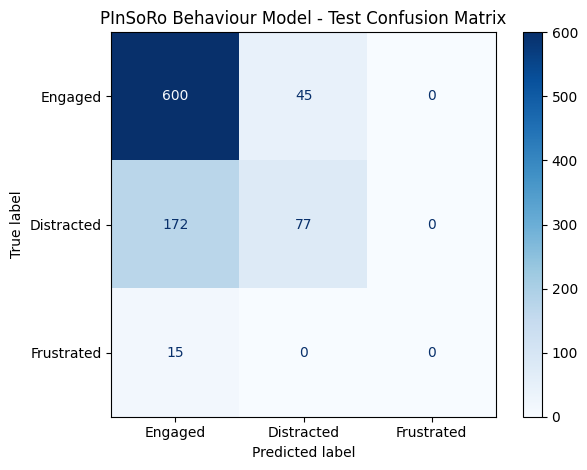

In [24]:
# ============================================================
# Cell 4 - PInSoRo Behaviour Model Test Evaluation
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)
import matplotlib.pyplot as plt
import numpy as np


# ============================================================
# 1. Predict TEST set
# ============================================================

test_probabilities = model.predict(
    X_test_scaled,
    verbose=0
)

y_test_pred = np.argmax(
    test_probabilities,
    axis=1
)


# ============================================================
# 2. Overall metrics
# ============================================================

test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)

test_macro_f1 = f1_score(
    y_test,
    y_test_pred,
    average="macro"
)

test_weighted_f1 = f1_score(
    y_test,
    y_test_pred,
    average="weighted"
)


print("=" * 70)
print("PInSoRo 3-Class Behaviour Model - TEST RESULTS")
print("=" * 70)

print(f"\nTest Accuracy  : {test_accuracy:.4f}")
print(f"Test Macro F1  : {test_macro_f1:.4f}")
print(f"Test Weighted F1: {test_weighted_f1:.4f}")


# ============================================================
# 3. Classification report
# ============================================================

class_names = [
    "Engaged",
    "Distracted",
    "Frustrated"
]

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        y_test_pred,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0,
        digits=4
    )
)


# ============================================================
# 4. Confusion Matrix
# ============================================================

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1, 2]
)

print("=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

print("\nRows = Actual")
print("Columns = Predicted\n")

print(cm)


# ============================================================
# 5. Frustrated-specific performance
# ============================================================

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_test,
        y_test_pred,
        labels=[0, 1, 2],
        zero_division=0
    )
)

print("\n" + "=" * 70)
print("FRUSTRATED CLASS PERFORMANCE")
print("=" * 70)

print(f"Precision : {precision[2]:.4f}")
print(f"Recall    : {recall[2]:.4f}")
print(f"F1-score  : {f1[2]:.4f}")
print(f"Support   : {support[2]}")


# ============================================================
# 6. Plot confusion matrix
# ============================================================

plt.figure(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("PInSoRo Behaviour Model - Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [25]:
# ============================================================
# Cell 5 - Feature Distribution Diagnostic
# ============================================================

import pandas as pd
import numpy as np

diagnostic = train_df.groupby(
    "behavior_state"
)[FEATURE_COLUMNS].agg(["mean", "std"])

pd.set_option("display.max_columns", None)

print("=" * 80)
print("TRAIN FEATURE DISTRIBUTION BY BEHAVIOUR")
print("=" * 80)

display(diagnostic)


# ------------------------------------------------------------
# Individual class means
# ------------------------------------------------------------

class_means = train_df.groupby(
    "behavior_state"
)[FEATURE_COLUMNS].mean()

print("\n" + "=" * 80)
print("CLASS MEANS")
print("=" * 80)

display(class_means)


# ------------------------------------------------------------
# Frustrated training samples
# ------------------------------------------------------------

frustrated_train = train_df[
    train_df["behavior_state"] == "Frustrated"
]

print("\n" + "=" * 80)
print("FRUSTRATED TRAINING SAMPLES")
print("=" * 80)

print("Number of Frustrated samples:", len(frustrated_train))

display(
    frustrated_train[
        ["session_id", "window_start", "window_end"]
        + FEATURE_COLUMNS
    ]
)

TRAIN FEATURE DISTRIBUTION BY BEHAVIOUR


pose_movement_mean           pose_movement_std            \
                             mean       std              mean       std   
behavior_state                                                            
Distracted               0.042229  0.032645          0.050480  0.047811   
Engaged                  0.054356  0.036454          0.058013  0.047872   
Frustrated               0.060975  0.021637          0.073918  0.049459   

               face_movement_mean           face_movement_std            \
                             mean       std              mean       std   
behavior_state                                                            
Distracted               0.061874  0.053456          0.081694  0.101933   
Engaged                  0.071837  0.068202          0.093883  0.113354   
Frustrated               0.093636  0.042524          0.125032  0.088944   

               hand_movement_mean           hand_movement_std            
                             mean       std              mean       std  
behavior_state                                                           
Distracted               0.092715  0.080792          0.144393  0.102443  
Engaged                  0.140588  0.078735          0.200621  0.080178  
Frustrated               0.120548  0.036169          0.159534  0.053194


CLASS MEANS


,pose_movement_mean,pose_movement_std,face_movement_mean,face_movement_std,hand_movement_mean,hand_movement_std
behavior_state,,,,,,
Distracted,0.042229,0.050480,0.061874,0.081694,0.092715,0.144393
Engaged,0.054356,0.058013,0.071837,0.093883,0.140588,0.200621
Frustrated,0.060975,0.073918,0.093636,0.125032,0.120548,0.159534



FRUSTRATED TRAINING SAMPLES
Number of Frustrated samples: 16


,session_id,window_start,window_end,pose_movement_mean,pose_movement_std,face_movement_mean,face_movement_std,hand_movement_mean,hand_movement_std
310,2017-06-13-140354392253,1.497360e+09,1.497360e+09,0.059742,0.043651,0.035944,0.009740,0.139687,0.188102
345,2017-06-13-140354392253,1.497360e+09,1.497360e+09,0.034382,0.061977,0.052624,0.116890,0.098759,0.144985
576,2017-06-13-140354392253,1.497360e+09,1.497360e+09,0.041884,0.031278,0.088904,0.085003,0.129590,0.182397
605,2017-06-13-140354392253,1.497360e+09,1.497360e+09,0.064842,0.081113,0.107090,0.206861,0.103740,0.191884
974,2017-06-13-140354392253,1.497360e+09,1.497360e+09,0.080043,0.076993,0.093528,0.110264,0.158670,0.245545
999,2017-06-13-140354392253,1.497360e+09,1.497360e+09,0.067853,0.095624,0.114144,0.200184,0.145772,0.165307
1265,2017-06-13-140354392253,1.497360e+09,1.497360e+09,0.080108,0.118874,0.126406,0.246476,0.103604,0.163079
1280,2017-06-13-140354392253,1.497360e+09,1.497360e+09,0.106311,0.188485,0.172224,0.269794,0.133470,0.173391
1364,2017-06-13-140354392253,1.497360e+09,1.497360e+09,0.071722,0.172986,0.165861,0.207463,0.101982,0.136939
1370,2017-06-13-140354392253,1.497360e+09,1.497360e+09,0.031182,0.023006,0.077217,0.080688,0.061469,0.065996


In [26]:
# ============================================================
# Cell 6 - Class-Weighted PInSoRo Behaviour Model
# ============================================================

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils.class_weight import compute_class_weight
import numpy as np


# ============================================================
# 1. Calculate class weights from TRAIN ONLY
# ============================================================

classes = np.array([0, 1, 2])

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, class_weights_array)
}

print("=" * 70)
print("CLASS WEIGHTS")
print("=" * 70)

print("0 = Engaged    :", class_weights[0])
print("1 = Distracted :", class_weights[1])
print("2 = Frustrated :", class_weights[2])


# ============================================================
# 2. Build NEW model
# ============================================================

weighted_model = Sequential([
    Input(shape=(6,)),

    Dense(64, activation="relu"),
    Dropout(0.30),

    Dense(32, activation="relu"),
    Dropout(0.20),

    Dense(3, activation="softmax")
])


# ============================================================
# 3. Compile
# ============================================================

weighted_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# ============================================================
# 4. Early stopping
# ============================================================

early_stopping_weighted = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)


# ============================================================
# 5. Train with class weights
# ============================================================

weighted_history = weighted_model.fit(
    X_train_scaled,
    y_train,

    validation_data=(
        X_val_scaled,
        y_val
    ),

    epochs=100,
    batch_size=32,

    class_weight=class_weights,

    callbacks=[
        early_stopping_weighted
    ],

    verbose=1
)


print("\n" + "=" * 70)
print("WEIGHTED TRAINING COMPLETE")
print("=" * 70)

print(
    "Epochs trained:",
    len(weighted_history.history["loss"])
)

CLASS WEIGHTS
0 = Engaged    : 0.4345372460496614
1 = Distracted : 1.475095785440613
2 = Frustrated : 48.125
Epoch 1/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.5329 - loss: 1.1100 - val_accuracy: 0.6081 - val_loss: 0.9031
Epoch 2/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5532 - loss: 1.0652 - val_accuracy: 0.6542 - val_loss: 0.8951
Epoch 3/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5455 - loss: 0.9903 - val_accuracy: 0.5965 - val_loss: 0.9013
Epoch 4/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5333 - loss: 0.9580 - val_accuracy: 0.5216 - val_loss: 0.9205
Epoch 5/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5377 - loss: 0.9514 - val_accuracy: 0.5389 - val_loss: 0.9024
Epoch 6/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5056 - loss: 0.8806 - val_accuracy: 0.5245 - val_loss: 0.9133
Epoch 7/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5173 - loss: 0.8729 - val_accuracy: 0.5706 - val_loss: 0.8869
Ep

WEIGHTED PInSoRo MODEL - TEST RESULTS

Test Accuracy   : 0.6293
Test Macro F1   : 0.4040
Test Weighted F1: 0.6477

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Engaged     0.7959    0.6651    0.7247       645
  Distracted     0.4231    0.5743    0.4872       249
  Frustrated     0.0000    0.0000    0.0000        15

    accuracy                         0.6293       909
   macro avg     0.4063    0.4131    0.4040       909
weighted avg     0.6807    0.6293    0.6477       909

CONFUSION MATRIX

Rows = Actual
Columns = Predicted

[[429 194  22]
 [ 96 143  10]
 [ 14   1   0]]

FRUSTRATED CLASS PERFORMANCE
Precision : 0.0000
Recall    : 0.0000
F1-score  : 0.0000
Support   : 15


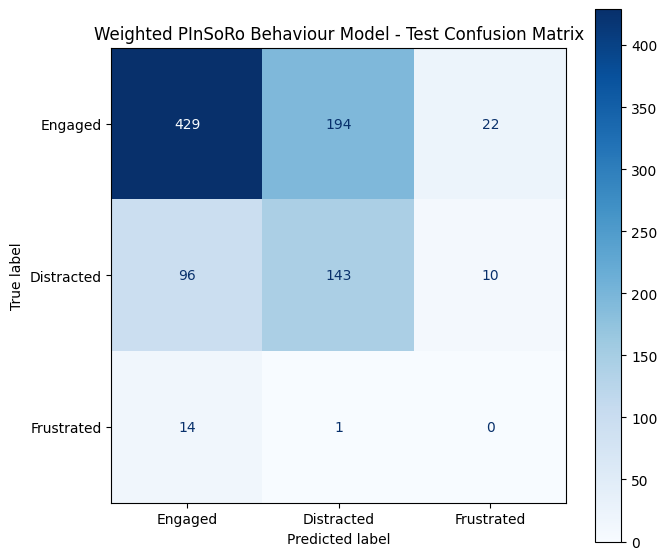

In [27]:
# ============================================================
# Cell 7 - Evaluate Weighted Model on Unseen Test Set
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    ConfusionMatrixDisplay
)
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. Predict TEST data
# ============================================================

weighted_test_probabilities = weighted_model.predict(
    X_test_scaled,
    verbose=0
)

weighted_y_test_pred = np.argmax(
    weighted_test_probabilities,
    axis=1
)


# ============================================================
# 2. Overall metrics
# ============================================================

weighted_accuracy = accuracy_score(
    y_test,
    weighted_y_test_pred
)

weighted_macro_f1 = f1_score(
    y_test,
    weighted_y_test_pred,
    average="macro"
)

weighted_f1 = f1_score(
    y_test,
    weighted_y_test_pred,
    average="weighted"
)


print("=" * 70)
print("WEIGHTED PInSoRo MODEL - TEST RESULTS")
print("=" * 70)

print(f"\nTest Accuracy   : {weighted_accuracy:.4f}")
print(f"Test Macro F1   : {weighted_macro_f1:.4f}")
print(f"Test Weighted F1: {weighted_f1:.4f}")


# ============================================================
# 3. Classification report
# ============================================================

class_names = [
    "Engaged",
    "Distracted",
    "Frustrated"
]

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        weighted_y_test_pred,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0,
        digits=4
    )
)


# ============================================================
# 4. Confusion Matrix
# ============================================================

weighted_cm = confusion_matrix(
    y_test,
    weighted_y_test_pred,
    labels=[0, 1, 2]
)

print("=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

print("\nRows = Actual")
print("Columns = Predicted\n")

print(weighted_cm)


# ============================================================
# 5. Frustrated performance
# ============================================================

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_test,
        weighted_y_test_pred,
        labels=[0, 1, 2],
        zero_division=0
    )
)

print("\n" + "=" * 70)
print("FRUSTRATED CLASS PERFORMANCE")
print("=" * 70)

print(f"Precision : {precision[2]:.4f}")
print(f"Recall    : {recall[2]:.4f}")
print(f"F1-score  : {f1[2]:.4f}")
print(f"Support   : {support[2]}")


# ============================================================
# 6. Confusion Matrix Plot
# ============================================================

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=weighted_cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

ax.set_title(
    "Weighted PInSoRo Behaviour Model - Test Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [28]:
# ============================================================
# STEP 1 - Verify Existing Behaviour Models
# ============================================================

import os

# ------------------------------------------------------------
# ASC Camera Behaviour Model
# ------------------------------------------------------------

ASC_MODEL_PATH = (
    "/content/drive/MyDrive/"
    "Dyslexia_Research_Model/"
    "best_behaviour_gru.pt"
)

ASC_SCALER_MEAN = (
    "/content/drive/MyDrive/"
    "Dyslexia_Research_Model/"
    "visual_sequences/scaler_mean.npy"
)

ASC_SCALER_SCALE = (
    "/content/drive/MyDrive/"
    "Dyslexia_Research_Model/"
    "visual_sequences/scaler_scale.npy"
)


# ------------------------------------------------------------
# Audio Frustration Model
# ------------------------------------------------------------

AUDIO_MODEL_PATH = (
    "/content/drive/MyDrive/"
    "Behavior Detection/"
    "EmoReact_V_1.0/EmoReact_V_1.0/"
    "audio_model/best_audio_frustration_model.pt"
)

AUDIO_SCALER_PATH = (
    "/content/drive/MyDrive/"
    "Behavior Detection/"
    "EmoReact_V_1.0/EmoReact_V_1.0/"
    "audio_model/audio_scaler.pkl"
)


# ------------------------------------------------------------
# Check files
# ------------------------------------------------------------

files_to_check = {
    "ASC model": ASC_MODEL_PATH,
    "ASC scaler mean": ASC_SCALER_MEAN,
    "ASC scaler scale": ASC_SCALER_SCALE,
    "Audio model": AUDIO_MODEL_PATH,
    "Audio scaler": AUDIO_SCALER_PATH
}


print("=" * 70)
print("MODEL FILE VERIFICATION")
print("=" * 70)

all_found = True

for name, path in files_to_check.items():

    exists = os.path.exists(path)

    status = "FOUND" if exists else "NOT FOUND"

    print(f"{name:22s}: {status}")

    if not exists:
        print("   Path:", path)
        all_found = False


print("\n" + "=" * 70)

if all_found:
    print("ALL REQUIRED MODEL FILES FOUND.")
else:
    print("SOME FILES ARE MISSING.")
    print("DO NOT CONTINUE TO MODEL LOADING YET.")

MODEL FILE VERIFICATION
ASC model             : FOUND
ASC scaler mean       : FOUND
ASC scaler scale      : FOUND
Audio model           : FOUND
Audio scaler          : FOUND

ALL REQUIRED MODEL FILES FOUND.


In [29]:
# ============================================================
# INTERACTION MODEL - STEP 1
# Load PInSoRo Train / Validation / Test
# ============================================================

import pandas as pd
import numpy as np

BASE_PATH = "/content/drive/MyDrive/Dyslexia_Research_Model/pinsoRo_behavior"

TRAIN_PATH = f"{BASE_PATH}/pinsoRo_train_v3.csv"
VAL_PATH   = f"{BASE_PATH}/pinsoRo_val_v3.csv"
TEST_PATH  = f"{BASE_PATH}/pinsoRo_test_v3.csv"

train_df = pd.read_csv(TRAIN_PATH)
val_df   = pd.read_csv(VAL_PATH)
test_df  = pd.read_csv(TEST_PATH)

print("=" * 70)
print("PInSoRo INTERACTION / BEHAVIOUR DATASET")
print("=" * 70)

print("\nTRAIN SHAPE :", train_df.shape)
print("VAL SHAPE   :", val_df.shape)
print("TEST SHAPE  :", test_df.shape)

print("\nTRAIN CLASSES:")
print(train_df["behavior_state"].value_counts())

print("\nVAL CLASSES:")
print(val_df["behavior_state"].value_counts())

print("\nTEST CLASSES:")
print(test_df["behavior_state"].value_counts())

print("\nFEATURE COLUMNS:")

feature_cols = [
    "pose_movement_mean",
    "pose_movement_std",
    "face_movement_mean",
    "face_movement_std",
    "hand_movement_mean",
    "hand_movement_std"
]

for i, col in enumerate(feature_cols):
    print(f"{i}: {col}")

print("\nMissing values:")
print("Train:", train_df[feature_cols].isna().sum().sum())
print("Val  :", val_df[feature_cols].isna().sum().sum())
print("Test :", test_df[feature_cols].isna().sum().sum())

print("\n" + "=" * 70)
print("STEP 1 COMPLETE")
print("=" * 70)

PInSoRo INTERACTION / BEHAVIOUR DATASET

TRAIN SHAPE : (2310, 13)
VAL SHAPE   : (347, 13)
TEST SHAPE  : (909, 13)

TRAIN CLASSES:
behavior_state
Engaged       1772
Distracted     522
Frustrated      16
Name: count, dtype: int64

VAL CLASSES:
behavior_state
Engaged       274
Distracted     73
Name: count, dtype: int64

TEST CLASSES:
behavior_state
Engaged       645
Distracted    249
Frustrated     15
Name: count, dtype: int64

FEATURE COLUMNS:
0: pose_movement_mean
1: pose_movement_std
2: face_movement_mean
3: face_movement_std
4: hand_movement_mean
5: hand_movement_std

Missing values:
Train: 0
Val  : 0
Test : 0

STEP 1 COMPLETE


In [30]:
# ============================================================
# INTERACTION MODEL - STEP 2
# Feature Preparation + Scaling + Label Encoding
# ============================================================

from sklearn.preprocessing import StandardScaler
import numpy as np

# ------------------------------------------------------------
# 1. Feature columns
# ------------------------------------------------------------

feature_cols = [
    "pose_movement_mean",
    "pose_movement_std",
    "face_movement_mean",
    "face_movement_std",
    "hand_movement_mean",
    "hand_movement_std"
]

# ------------------------------------------------------------
# 2. Extract features
# ------------------------------------------------------------

X_train_raw = train_df[feature_cols].values
X_val_raw   = val_df[feature_cols].values
X_test_raw  = test_df[feature_cols].values


# ------------------------------------------------------------
# 3. StandardScaler
# IMPORTANT:
# Fit ONLY on training data
# ------------------------------------------------------------

interaction_scaler = StandardScaler()

X_train = interaction_scaler.fit_transform(X_train_raw)
X_val   = interaction_scaler.transform(X_val_raw)
X_test  = interaction_scaler.transform(X_test_raw)


# ------------------------------------------------------------
# 4. Label mapping
# ------------------------------------------------------------

label_mapping = {
    "Engaged": 0,
    "Distracted": 1,
    "Frustrated": 2
}

y_train = train_df["behavior_state"].map(label_mapping).values
y_val   = val_df["behavior_state"].map(label_mapping).values
y_test  = test_df["behavior_state"].map(label_mapping).values


# ------------------------------------------------------------
# 5. Verify shapes
# ------------------------------------------------------------

print("=" * 70)
print("FEATURE PREPARATION")
print("=" * 70)

print("\nFeature columns:")
for i, col in enumerate(feature_cols):
    print(f"{i}: {col}")

print("\nFeature matrix shapes:")
print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

print("\nLabel shapes:")
print("y_train:", y_train.shape)
print("y_val  :", y_val.shape)
print("y_test :", y_test.shape)

print("\nLabel mapping:")
print(label_mapping)


# ------------------------------------------------------------
# 6. Check encoded label distribution
# ------------------------------------------------------------

print("\nEncoded training labels:")
print(np.bincount(y_train))

print("\nEncoded validation labels:")
print(np.bincount(y_val))

print("\nEncoded test labels:")
print(np.bincount(y_test))


# ------------------------------------------------------------
# 7. Check missing values
# ------------------------------------------------------------

print("\nMissing values after scaling:")
print("Train:", np.isnan(X_train).sum())
print("Val  :", np.isnan(X_val).sum())
print("Test :", np.isnan(X_test).sum())


# ------------------------------------------------------------
# 8. Check scaled training statistics
# ------------------------------------------------------------

print("\nTraining feature means after scaling:")
print(np.round(X_train.mean(axis=0), 4))

print("\nTraining feature standard deviations after scaling:")
print(np.round(X_train.std(axis=0), 4))


print("\n" + "=" * 70)
print("STEP 2 COMPLETE")
print("=" * 70)

FEATURE PREPARATION

Feature columns:
0: pose_movement_mean
1: pose_movement_std
2: face_movement_mean
3: face_movement_std
4: hand_movement_mean
5: hand_movement_std

Feature matrix shapes:
X_train: (2310, 6)
X_val  : (347, 6)
X_test : (909, 6)

Label shapes:
y_train: (2310,)
y_val  : (347,)
y_test : (909,)

Label mapping:
{'Engaged': 0, 'Distracted': 1, 'Frustrated': 2}

Encoded training labels:
[1772  522   16]

Encoded validation labels:
[274  73]

Encoded test labels:
[645 249  15]

Missing values after scaling:
Train: 0
Val  : 0
Test : 0

Training feature means after scaling:
[ 0. -0.  0.  0. -0. -0.]

Training feature standard deviations after scaling:
[1. 1. 1. 1. 1. 1.]

STEP 2 COMPLETE


In [31]:
# ============================================================
# INTERACTION MODEL - STEP 3
# Neural Network + Class Weights + Early Stopping
# ============================================================

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import os

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)


# ------------------------------------------------------------
# Class weights
# ------------------------------------------------------------

classes = np.array([0, 1, 2])

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, class_weights_array)
}

print("=" * 70)
print("CLASS WEIGHTS")
print("=" * 70)

print("0 = Engaged    :", class_weights[0])
print("1 = Distracted :", class_weights[1])
print("2 = Frustrated :", class_weights[2])


# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

interaction_model = Sequential([

    Input(shape=(6,)),

    Dense(64, activation="relu"),
    Dropout(0.30),

    Dense(32, activation="relu"),
    Dropout(0.20),

    Dense(3, activation="softmax")
])


# ------------------------------------------------------------
# Compile
# ------------------------------------------------------------

interaction_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# ------------------------------------------------------------
# Model summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL ARCHITECTURE")
print("=" * 70)

interaction_model.summary()


# ------------------------------------------------------------
# Save best model
# ------------------------------------------------------------

INTERACTION_MODEL_PATH = (
    "/content/drive/MyDrive/"
    "Dyslexia_Research_Model/"
    "pinsoRo_behavior/"
    "best_interaction_model.keras"
)


# ------------------------------------------------------------
# Callbacks
# ------------------------------------------------------------

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    INTERACTION_MODEL_PATH,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)


# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TRAINING INTERACTION MODEL")
print("=" * 70)

history = interaction_model.fit(
    X_train,
    y_train,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=100,
    batch_size=32,

    class_weight=class_weights,

    callbacks=[
        early_stopping,
        checkpoint
    ],

    verbose=1
)


print("\n" + "=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)

print("Epochs trained:", len(history.history["loss"]))
print("Best model saved to:")
print(INTERACTION_MODEL_PATH)

CLASS WEIGHTS
0 = Engaged    : 0.4345372460496614
1 = Distracted : 1.475095785440613
2 = Frustrated : 48.125

MODEL ARCHITECTURE


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,627 (10.26 KB)

 Trainable params: 2,627 (10.26 KB)

 Non-trainable params: 0 (0.00 B)


TRAINING INTERACTION MODEL
Epoch 1/100
66/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5499 - loss: 1.1597
Epoch 1: val_loss improved from None to 0.83594, saving model to /content/drive/MyDrive/Dyslexia_Research_Model/pinsoRo_behavior/best_interaction_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Dyslexia_Research_Model/pinsoRo_behavior/best_interaction_model.keras
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.5740 - loss: 1.1007 - val_accuracy: 0.7176 - val_loss: 0.8359
Epoch 2/100
69/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5489 - loss: 1.0274
Epoch 2: val_loss did not improve from 0.83594
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5515 - loss: 0.9961 - val_accuracy: 0.6945 - val_loss: 0.8403
Epoch 3/100
70/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5464 - loss: 1.0317
Epoch 3: val_loss did not improve from 0.83594
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5524 - loss: 1.0019 - val_accuracy: 0.6484 - val_loss:

INTERACTION MODEL - FINAL TEST RESULTS

Test Accuracy: 0.6381
Test Accuracy: 63.81%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Engaged     0.7949    0.6791    0.7324       645
  Distracted     0.4176    0.5703    0.4822       249
  Frustrated     0.0000    0.0000    0.0000        15

    accuracy                         0.6381       909
   macro avg     0.4042    0.4165    0.4049       909
weighted avg     0.6785    0.6381    0.6518       909


CONFUSION MATRIX

Rows = Actual
Columns = Predicted

[[438 197  10]
 [ 99 142   8]
 [ 14   1   0]]

FRUSTRATED CLASS PERFORMANCE
Precision : 0.0000
Recall    : 0.0000
F1-score  : 0.0000
Support   : 15


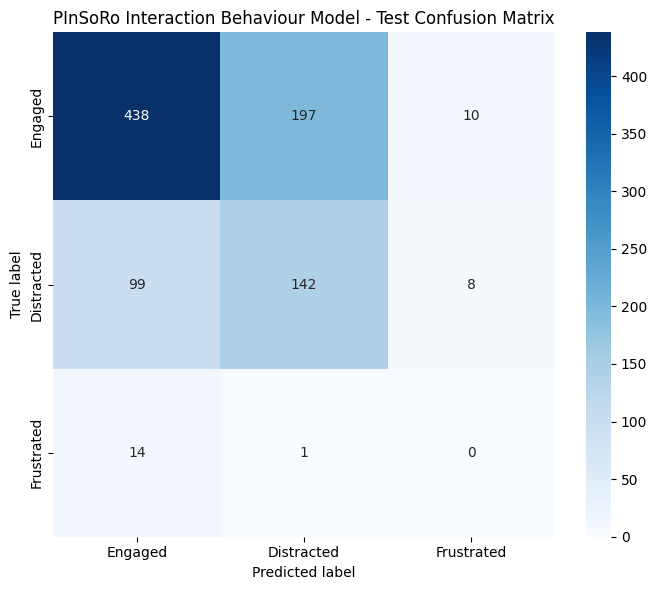


PREDICTION DISTRIBUTION
Engaged     : 551
Distracted  : 340
Frustrated  : 18


In [32]:
# ============================================================
# INTERACTION MODEL - STEP 4
# FINAL TEST EVALUATION
# ============================================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support
)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# ------------------------------------------------------------
# 1. Load best model
# ------------------------------------------------------------

best_interaction_model = tf.keras.models.load_model(
    INTERACTION_MODEL_PATH
)


# ------------------------------------------------------------
# 2. Predict TEST set
# ------------------------------------------------------------

y_prob = best_interaction_model.predict(
    X_test,
    verbose=0
)

y_pred = np.argmax(y_prob, axis=1)


# ------------------------------------------------------------
# 3. Class names
# ------------------------------------------------------------

class_names = [
    "Engaged",
    "Distracted",
    "Frustrated"
]


# ------------------------------------------------------------
# 4. Accuracy
# ------------------------------------------------------------

test_accuracy = accuracy_score(
    y_test,
    y_pred
)

print("=" * 70)
print("INTERACTION MODEL - FINAL TEST RESULTS")
print("=" * 70)

print(f"\nTest Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


# ------------------------------------------------------------
# 5. Classification report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2],
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# ------------------------------------------------------------
# 6. Confusion Matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1, 2]
)

print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

print("\nRows = Actual")
print("Columns = Predicted\n")

print(cm)


# ------------------------------------------------------------
# 7. Frustrated-specific performance
# ------------------------------------------------------------

precision, recall, f1, support = precision_recall_fscore_support(
    y_test,
    y_pred,
    labels=[2],
    zero_division=0
)

print("\n" + "=" * 70)
print("FRUSTRATED CLASS PERFORMANCE")
print("=" * 70)

print(f"Precision : {precision[0]:.4f}")
print(f"Recall    : {recall[0]:.4f}")
print(f"F1-score  : {f1[0]:.4f}")
print(f"Support   : {support[0]}")


# ------------------------------------------------------------
# 8. Plot confusion matrix
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("PInSoRo Interaction Behaviour Model - Test Confusion Matrix")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Prediction distribution
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PREDICTION DISTRIBUTION")
print("=" * 70)

for i, name in enumerate(class_names):
    count = np.sum(y_pred == i)
    print(f"{name:12s}: {count}")

In [33]:
# ============================================================
# INTERACTION MODEL - STEP 5
# Final Prediction Function
# ============================================================

# Load the best saved model
interaction_model = tf.keras.models.load_model(
    INTERACTION_MODEL_PATH
)

INTERACTION_CLASSES = {
    0: "Engaged",
    1: "Distracted",
    2: "Frustrated"
}


def predict_interaction_behavior(features):
    """
    Predict behaviour from 6 PInSoRo interaction/movement features.

    Feature order:
    0 - pose_movement_mean
    1 - pose_movement_std
    2 - face_movement_mean
    3 - face_movement_std
    4 - hand_movement_mean
    5 - hand_movement_std
    """

    features = np.asarray(features, dtype=np.float32)

    # Make sure input is 2D
    if features.ndim == 1:
        features = features.reshape(1, -1)

    # Apply the SAME scaler fitted on training data
    features_scaled = interaction_scaler.transform(features)

    # Prediction
    probabilities = interaction_model.predict(
        features_scaled,
        verbose=0
    )[0]

    predicted_class = int(np.argmax(probabilities))
    predicted_label = INTERACTION_CLASSES[predicted_class]

    return {
        "prediction": predicted_label,
        "engaged_probability": float(probabilities[0]),
        "distracted_probability": float(probabilities[1]),
        "frustrated_probability": float(probabilities[2])
    }


print("=" * 70)
print("INTERACTION PREDICTION FUNCTION READY")
print("=" * 70)

print("\nClasses:")
print(INTERACTION_CLASSES)

INTERACTION PREDICTION FUNCTION READY

Classes:
{0: 'Engaged', 1: 'Distracted', 2: 'Frustrated'}


In [34]:
# ============================================================
# STEP 6 - TEST INTERACTION PREDICTION
# ============================================================

# Use one real sample from the TEST dataset
sample = X_test[0]

result = predict_interaction_behavior(sample)

print("=" * 70)
print("REAL INTERACTION SAMPLE PREDICTION")
print("=" * 70)

print(f"\nPrediction : {result['prediction']}")

print(f"Engaged probability    : "
      f"{result['engaged_probability'] * 100:.2f}%")

print(f"Distracted probability : "
      f"{result['distracted_probability'] * 100:.2f}%")

print(f"Frustrated probability : "
      f"{result['frustrated_probability'] * 100:.2f}%")

REAL INTERACTION SAMPLE PREDICTION

Prediction : Distracted
Engaged probability    : 0.00%
Distracted probability : 100.00%
Frustrated probability : 0.00%


In [35]:
# ============================================================
# STEP 7 - INTERACTION MODEL SANITY CHECK
# Test multiple real test samples
# ============================================================

print("=" * 70)
print("INTERACTION MODEL - MULTIPLE SAMPLE SANITY CHECK")
print("=" * 70)

sample_count = 10

for i in range(sample_count):

    result = predict_interaction_behavior(X_test[i])

    print(
        f"\nSample {i+1:02d} | "
        f"Prediction: {result['prediction']:<11} | "
        f"Engaged: {result['engaged_probability']*100:6.2f}% | "
        f"Distracted: {result['distracted_probability']*100:6.2f}% | "
        f"Frustrated: {result['frustrated_probability']*100:6.2f}%"
    )

print("\n" + "=" * 70)
print("SANITY CHECK COMPLETE")
print("=" * 70)

INTERACTION MODEL - MULTIPLE SAMPLE SANITY CHECK

Sample 01 | Prediction: Distracted  | Engaged:   0.00% | Distracted: 100.00% | Frustrated:   0.00%

Sample 02 | Prediction: Distracted  | Engaged:  21.13% | Distracted:  78.87% | Frustrated:   0.00%

Sample 03 | Prediction: Engaged     | Engaged:  94.38% | Distracted:   5.62% | Frustrated:   0.00%

Sample 04 | Prediction: Engaged     | Engaged:  79.27% | Distracted:  20.73% | Frustrated:   0.00%

Sample 05 | Prediction: Engaged     | Engaged: 100.00% | Distracted:   0.00% | Frustrated:   0.00%

Sample 06 | Prediction: Engaged     | Engaged:  92.07% | Distracted:   7.93% | Frustrated:   0.00%

Sample 07 | Prediction: Distracted  | Engaged:   0.07% | Distracted:  99.93% | Frustrated:   0.00%

Sample 08 | Prediction: Distracted  | Engaged:   0.00% | Distracted: 100.00% | Frustrated:   0.00%

Sample 09 | Prediction: Distracted  | Engaged:   0.00% | Distracted: 100.00% | Frustrated:   0.00%

Sample 10 | Prediction: Engaged     | Engaged:  95

In [36]:
# ============================================================
# STEP 7 - MULTIMODAL BEHAVIOUR FUSION
# Camera + Voice + Interaction
# ============================================================

import numpy as np


def fuse_behaviour_predictions(
    camera_probs,
    voice_frustrated_prob,
    interaction_probs
):
    """
    Multimodal fusion of:

    Camera      -> 3-class
    Voice       -> Frustrated / Non-Frustrated
    Interaction -> 3-class

    Class order:
    0 = Engaged
    1 = Distracted
    2 = Frustrated
    """

    # --------------------------------------------------------
    # FUSION WEIGHTS
    # --------------------------------------------------------
    CAMERA_WEIGHT = 0.55
    INTERACTION_WEIGHT = 0.30
    VOICE_WEIGHT = 0.15

    # Convert inputs to numpy arrays
    camera_probs = np.asarray(camera_probs, dtype=np.float32)
    interaction_probs = np.asarray(
        interaction_probs,
        dtype=np.float32
    )

    voice_frustrated_prob = float(voice_frustrated_prob)

    # --------------------------------------------------------
    # Safety checks
    # --------------------------------------------------------

    if len(camera_probs) != 3:
        raise ValueError(
            "Camera probabilities must contain 3 values."
        )

    if len(interaction_probs) != 3:
        raise ValueError(
            "Interaction probabilities must contain 3 values."
        )

    # Normalize camera probabilities
    camera_probs = camera_probs / (
        camera_probs.sum() + 1e-8
    )

    # Normalize interaction probabilities
    interaction_probs = interaction_probs / (
        interaction_probs.sum() + 1e-8
    )

    # Keep voice probability within [0, 1]
    voice_frustrated_prob = np.clip(
        voice_frustrated_prob,
        0.0,
        1.0
    )

    # --------------------------------------------------------
    # Voice contributes mainly to FRUSTRATED evidence
    # --------------------------------------------------------

    voice_probs = np.array([
        (1.0 - voice_frustrated_prob) * 0.5,
        (1.0 - voice_frustrated_prob) * 0.5,
        voice_frustrated_prob
    ])

    # --------------------------------------------------------
    # Weighted fusion
    # --------------------------------------------------------

    fused_probs = (
        CAMERA_WEIGHT * camera_probs
        + INTERACTION_WEIGHT * interaction_probs
        + VOICE_WEIGHT * voice_probs
    )

    # Normalize final probabilities
    fused_probs = fused_probs / (
        fused_probs.sum() + 1e-8
    )

    # --------------------------------------------------------
    # Final prediction
    # --------------------------------------------------------

    class_names = [
        "Engaged",
        "Distracted",
        "Frustrated"
    ]

    predicted_index = int(
        np.argmax(fused_probs)
    )

    predicted_label = class_names[
        predicted_index
    ]

    return {
        "prediction": predicted_label,
        "engaged_probability": float(fused_probs[0]),
        "distracted_probability": float(fused_probs[1]),
        "frustrated_probability": float(fused_probs[2])
    }


print("=" * 70)
print("MULTIMODAL FUSION FUNCTION READY")
print("=" * 70)

print("\nModalities:")
print("Camera      -> 3-class behaviour")
print("Voice       -> frustration evidence")
print("Interaction -> 3-class behaviour")

print("\nFusion weights:")
print("Camera      : 55%")
print("Interaction : 30%")
print("Voice       : 15%")

print("\nClasses:")
print("0 = Engaged")
print("1 = Distracted")
print("2 = Frustrated")

MULTIMODAL FUSION FUNCTION READY

Modalities:
Camera      -> 3-class behaviour
Voice       -> frustration evidence
Interaction -> 3-class behaviour

Fusion weights:
Camera      : 55%
Interaction : 30%
Voice       : 15%

Classes:
0 = Engaged
1 = Distracted
2 = Frustrated


In [37]:
# ============================================================
# STEP 7.1 - TEST MULTIMODAL FUSION
# ============================================================

# Example probabilities
# Camera -> 3 classes
camera_test_probs = np.array([
    0.70,   # Engaged
    0.20,   # Distracted
    0.10    # Frustrated
])

# Voice -> Frustrated probability only
voice_test_frustrated = 0.15

# Interaction -> 3 classes
interaction_test_probs = np.array([
    0.60,   # Engaged
    0.35,   # Distracted
    0.05    # Frustrated
])


# Run fusion
fusion_result = fuse_behaviour_predictions(
    camera_probs=camera_test_probs,
    voice_frustrated_prob=voice_test_frustrated,
    interaction_probs=interaction_test_probs
)


# Display result
print("=" * 70)
print("MULTIMODAL FUSION TEST")
print("=" * 70)

print(f"\nFinal Prediction : {fusion_result['prediction']}")

print(
    f"Engaged probability    : "
    f"{fusion_result['engaged_probability'] * 100:.2f}%"
)

print(
    f"Distracted probability : "
    f"{fusion_result['distracted_probability'] * 100:.2f}%"
)

print(
    f"Frustrated probability : "
    f"{fusion_result['frustrated_probability'] * 100:.2f}%"
)

MULTIMODAL FUSION TEST

Final Prediction : Engaged
Engaged probability    : 62.87%
Distracted probability : 27.87%
Frustrated probability : 9.25%


In [38]:
# ============================================================
# STEP 8 - CAMERA MODEL PREDICTION FUNCTION
# ============================================================

import numpy as np


CAMERA_CLASSES = {
    0: "Engaged",
    1: "Distracted",
    2: "Frustrated"
}


def predict_camera_behavior(camera_sequence):
    """
    Predict behaviour from a 30-frame camera sequence.

    Expected input:
        (30, 1503)

    Output:
        3-class probabilities
    """

    camera_sequence = np.asarray(
        camera_sequence,
        dtype=np.float32
    )

    # --------------------------------------------------------
    # Check input shape
    # --------------------------------------------------------

    if camera_sequence.shape != (30, 1503):
        raise ValueError(
            f"Expected camera input shape (30, 1503), "
            f"but received {camera_sequence.shape}"
        )

    # --------------------------------------------------------
    # Apply ASC scaler
    # --------------------------------------------------------

    camera_sequence_scaled = (
        camera_sequence - asc_mean
    ) / (asc_scale + 1e-8)

    # --------------------------------------------------------
    # Add batch dimension
    # --------------------------------------------------------

    camera_input = np.expand_dims(
        camera_sequence_scaled,
        axis=0
    )

    # --------------------------------------------------------
    # Camera GRU prediction
    # --------------------------------------------------------

    probabilities = camera_model.predict(
        camera_input,
        verbose=0
    )[0]

    # --------------------------------------------------------
    # Normalize
    # --------------------------------------------------------

    probabilities = probabilities / (
        probabilities.sum() + 1e-8
    )

    predicted_index = int(
        np.argmax(probabilities)
    )

    predicted_label = CAMERA_CLASSES[
        predicted_index
    ]

    return {
        "prediction": predicted_label,
        "engaged_probability": float(probabilities[0]),
        "distracted_probability": float(probabilities[1]),
        "frustrated_probability": float(probabilities[2])
    }


print("=" * 70)
print("CAMERA PREDICTION FUNCTION READY")
print("=" * 70)

print("\nClasses:")
print(CAMERA_CLASSES)

CAMERA PREDICTION FUNCTION READY

Classes:
{0: 'Engaged', 1: 'Distracted', 2: 'Frustrated'}
